In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, CSVLogger
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [ ]:
# ✅ SECTION 2: Set dataset path
base_dir = '/content/drive/MyDrive/data'

In [ ]:
# ✅ SECTION 3: Image preprocessing
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'valid'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 321 images belonging to 2 classes.
Found 81 images belonging to 2 classes.
Found 71 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.applications import VGG19
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Load pre-trained VGG19 model (excluding the top classification layer)
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

# Freeze the base model layers
for layer in base_model.layers:
    layer.trainable = False

# Add custom classification layers
x = base_model.output
x = Flatten()(x)
x = Dense(4096, activation='relu')(x)
x = Dense(4096, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)  # Assuming 2 classes

# Create the new model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model (you might want to adjust epochs and batch size)
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10  # You might need more epochs for better accuracy
)




80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
 6/11 ━━━━━━━━━━━━━━━━━━━━ 1:58 24s/step - accuracy: 0.5798 - loss: 2.5520

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


11/11 ━━━━━━━━━━━━━━━━━━━━ 383s 34s/step - accuracy: 0.5728 - loss: 2.4585 - val_accuracy: 0.7284 - val_loss: 0.5177
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 361s 33s/step - accuracy: 0.6735 - loss: 0.6315 - val_accuracy: 0.7654 - val_loss: 0.5239
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 337s 31s/step - accuracy: 0.9126 - loss: 0.2531 - val_accuracy: 0.7901 - val_loss: 0.4896
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 359s 33s/step - accuracy: 0.9413 - loss: 0.1808 - val_accuracy: 0.8148 - val_loss: 0.3175
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 335s 33s/step - accuracy: 0.9765 - loss: 0.0852 - val_accuracy: 0.8272 - val_loss: 0.2896
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 388s 31s/step - accuracy: 0.9879 - loss: 0.0455 - val_accuracy: 0.8395 - val_loss: 0.3092
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 336s 31s/step - accuracy: 0.9958 - loss: 0.0241 - val_accuracy: 0.8519 - val_loss: 0.3469
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 344s 32s/step - accuracy: 1.0000 - loss: 0.0131 - val_accuracy: 0.8519 - val_

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {accuracy:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 57s 15s/step - accuracy: 0.9601 - loss: 0.0970
Test Accuracy: 0.94


In [ ]:
# prompt: save model to drive

# ✅ SECTION 7: Save the model to Google Drive
model.save('/content/drive/MyDrive/pre_trained_vgg19_model.h5')
print("Model saved successfully to Google Drive.")


Model saved successfully to Google Drive.


3/3 ━━━━━━━━━━━━━━━━━━━━ 67s 16s/step


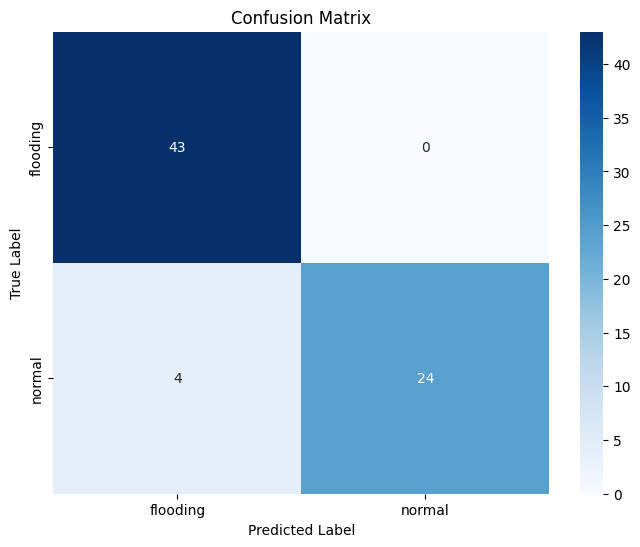

In [ ]:
# prompt: show confussion matrix

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get predictions on the test set
predictions = model.predict(test_gen)
predicted_classes = np.argmax(predictions, axis=1)

# Get true labels from the test generator
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# Compute the confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
<ipython-input-14-4bad0bba0808>:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


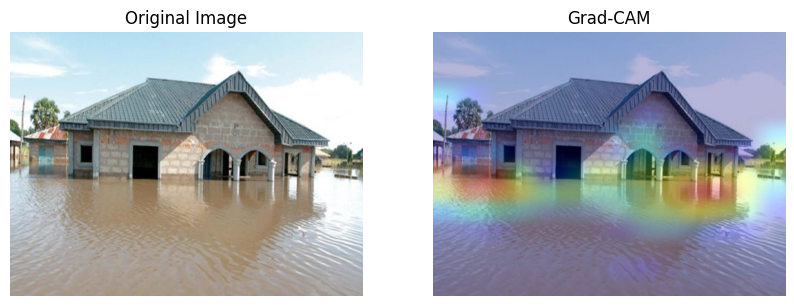

In [ ]:
# prompt: apply gradcam and display gradcam image and   original image seperatly

import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.cm as cm
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Ensure the model takes raw input image array
    grad_model = tf.keras.models.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    img = image.load_img(img_path)
    img = image.img_to_array(img)

    # Rescale heatmap to a range 0-255
    heatmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")

    # Use RGB values of the colormap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = image.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = image.array_to_img(superimposed_img)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(image.array_to_img(img))
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(superimposed_img)
    plt.title("Grad-CAM")
    plt.axis('off')
    plt.show()

# --- Example Usage ---

# Get the path to an image from the test set
# You might need to adjust this path based on your dataset structure
# This example assumes the first image in the test set
first_test_image_path = test_gen.filepaths[0]

# Preprocess the image for the model
img_array = image.load_img(first_test_image_path, target_size=(IMG_SIZE, IMG_SIZE))
img_array = image.img_to_array(img_array)
img_array = np.expand_dims(img_array, axis=0)
# Remember to rescale if your model was trained with rescaling
# If your model was trained with rescale=1./255, then uncomment the line below
img_array = img_array / 255.0


# Define the name of the last convolutional layer
# You can inspect model.summary() to find this name, typically it's something like 'block5_conv4' for VGG19
last_conv_layer_name = 'block5_conv4'

# Generate the Grad-CAM heatmap
heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

# Display the original image and the Grad-CAM image
display_gradcam(first_test_image_path, heatmap)


# for i in range(5):
#     img_path = test_gen.filepaths[i]
#     img_array = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
#     img_array = image.img_to_array(img_array)
#     img_array = np.expand_dims(img_array, axis=0)
#     img_array = img_array / 255.0 # Uncomment if rescaling was used
#
#     heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)
#     print(f"Grad-CAM for image: {img_path}")
#     display_gradcam(img_path, heatmap)